<a href="https://colab.research.google.com/github/vroos001/CYSE-635/blob/main/CYSE635_Adversarial_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import **Pytorch** libraries and APIs.


In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.datasets
from torch.utils.data import Subset
from torch.autograd import Variable
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F

# define the function of displaying multiple images
def show_images(images) -> None:
    n: int = images.size(0)

    f = plt.figure(figsize=(24, 6))
    for i in range(n):
        # Debug, plot figure
        f.add_subplot(1, n, i + 1)
        plt.imshow(images[i].cpu().squeeze(), cmap='gray')
        plt.axis('off')

    plt.show(block=True)

# define the function of displaying multiple images
def show_images_withPred(images,label,pred,conf) -> None:
    n: int = images.size(0)

    f = plt.figure(figsize=(24, 6))
    for i in range(n):
        # Debug, plot figure
        f.add_subplot(1, n, i + 1)
        plt.imshow(images[i].cpu().squeeze(), cmap='gray')
        plt.title("{} -> {}".format(label[i], pred[i]))
        #plt.title("Conf:{} \n {} -> {}".format(conf[i][pred[i]]*100,label[i], pred[i]))
        plt.axis('off')

    plt.show(block=True)


In [2]:
# Hyperparameters and Data loaders
num_epochs = 10
num_classes = 10
batch_size = 256
learning_rate = 0.001


DATA_PATH = 'data/'
MODEL_STORE_PATH = 'models/'

# transforms to apply to the data
trans = transforms.Compose([transforms.ToTensor()])

# MNIST dataset
train_dataset = torchvision.datasets.MNIST(root=DATA_PATH, train=True, transform=trans, download=True)
test_dataset = torchvision.datasets.MNIST(root=DATA_PATH, train=False, transform=trans)

# Data loader
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, num_workers=4, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, num_workers=4, shuffle=False)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.17MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 135kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.27MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.5MB/s]
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [3]:
# CNN
class LeNet(nn.Module):
    def __init__(self):
        super(LeNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(1, -1),
        )
        self.fc1 = nn.Linear(7 * 7 * 16, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
        self.dropout=nn.Dropout(0.3)

    def forward(self, x):
        out = self.features(x)
        out = self.dropout(self.fc1(out))
        out = self.dropout(self.fc2(out))
        out = self.fc3(out)

        return out


model=LeNet()
model.cuda()
model.train()

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [4]:
model.train()
loss_list_cnn = []
acc_list_cnn = []
total_step = len(train_loader)

for epoch in range(num_epochs):
  for i, (images, labels) in enumerate(train_loader):
    images = images.cuda()
    labels = labels.cuda()

    outputs = model(images)

    loss = criterion(outputs, labels)
    loss_list_cnn.append(loss.item())

    # Backprop and percform Adam optimisation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Track the accuracy
    total = labels.size(0)
    _, predicted = torch.max(outputs.data, 1)
    correct = (predicted == labels).sum().item()
    acc_list_cnn.append(correct / total)

    if (i%150 == 0):
      print('Epoch [{}/{}], Step [{}/{}], Loss: {:.4f}, Accuracy: {:.2f}%'
              .format(epoch + 1, num_epochs, i, total_step, loss.item(),
                      (correct / total) * 100))


model.eval()
with torch.no_grad():
  correct = 0
  total = 0
  for images, labels in test_loader:
      images = images.cuda()
      labels = labels.cuda()

      outputs = model(images)
      _, predicted = torch.max(outputs.data, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()

print(
  'Accuracy of the model on the 10000 test images: {} %'.format((correct / total) * 100))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [1/10], Step [0/235], Loss: 2.3071, Accuracy: 10.16%
Epoch [1/10], Step [150/235], Loss: 0.2326, Accuracy: 92.58%
Epoch [2/10], Step [0/235], Loss: 0.1694, Accuracy: 95.31%
Epoch [2/10], Step [150/235], Loss: 0.1057, Accuracy: 98.44%
Epoch [3/10], Step [0/235], Loss: 0.1012, Accuracy: 96.88%
Epoch [3/10], Step [150/235], Loss: 0.1183, Accuracy: 95.70%
Epoch [4/10], Step [0/235], Loss: 0.1746, Accuracy: 96.48%
Epoch [4/10], Step [150/235], Loss: 0.0588, Accuracy: 98.05%
Epoch [5/10], Step [0/235], Loss: 0.0270, Accuracy: 100.00%
Epoch [5/10], Step [150/235], Loss: 0.0957, Accuracy: 98.44%
Epoch [6/10], Step [0/235], Loss: 0.0572, Accuracy: 98.44%
Epoch [6/10], Step [150/235], Loss: 0.0836, Accuracy: 97.27%
Epoch [7/10], Step [0/235], Loss: 0.0634, Accuracy: 98.05%
Epoch [7/10], Step [150/235], Loss: 0.0851, Accuracy: 97.66%
Epoch [8/10], Step [0/235], Loss: 0.0286, Accuracy: 98.83%
Epoch [8/10], Step [150/235], Loss: 0.0310, Accuracy: 98.83%
Epoch [9/10], Step [0/235], Loss: 0.038

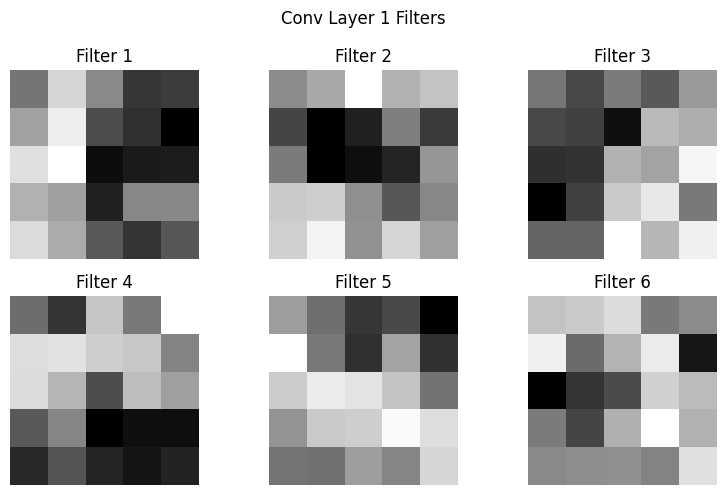

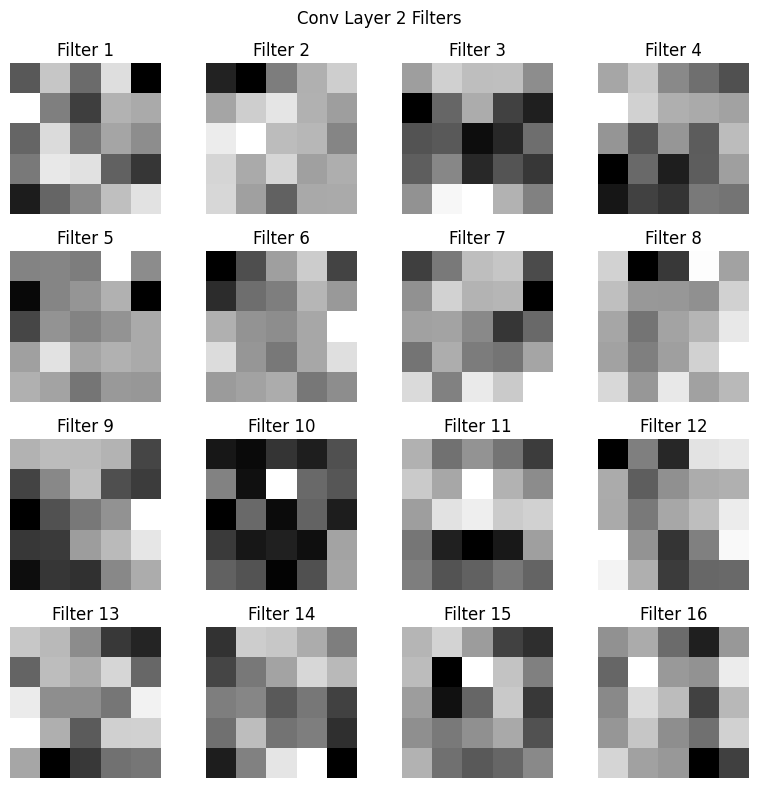

In [5]:
# Visualize filters from the first convolutional layer
conv1_filters = model.features[0].weight.detach().cpu()

fig, axes = plt.subplots(2, 3, figsize=(8, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(conv1_filters[i, 0], cmap='gray')
    ax.set_title(f'Filter {i + 1}')
    ax.axis('off')

plt.suptitle('Conv Layer 1 Filters')
plt.tight_layout()
plt.show()

# Visualize filters from the second convolutional layer
conv2_filters = model.features[3].weight.detach().cpu()

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    filter_image = conv2_filters[i].mean(dim=0)
    ax.imshow(filter_image, cmap='gray')
    ax.set_title(f'Filter {i + 1}')
    ax.axis('off')

plt.suptitle('Conv Layer 2 Filters')
plt.tight_layout()
plt.show()

Incorrect Predictions:


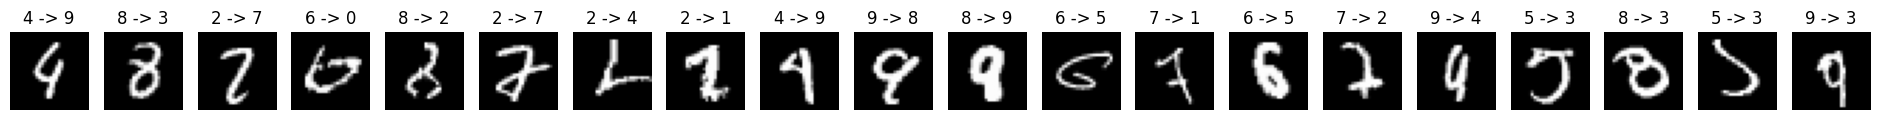

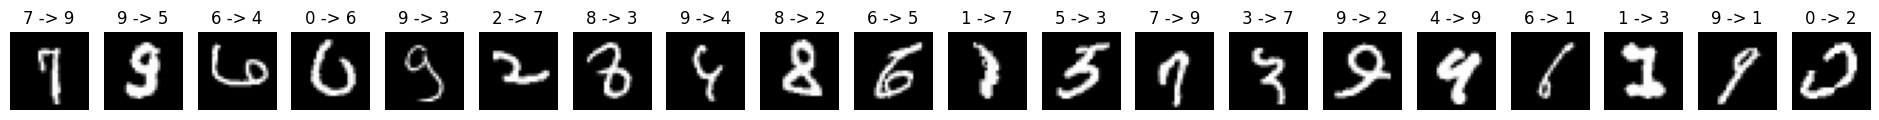

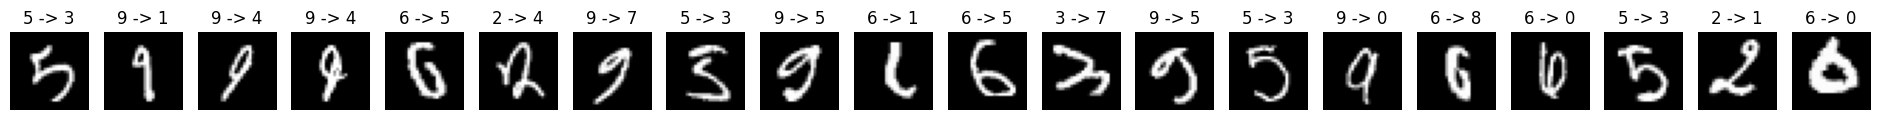

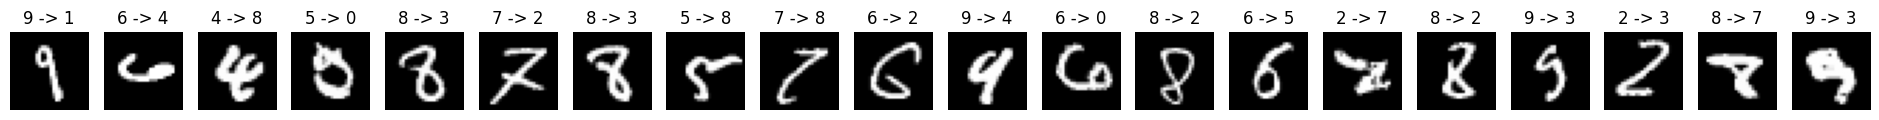



Correct Predictions:


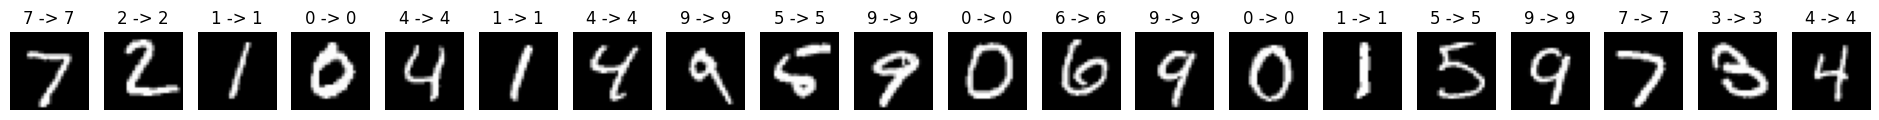

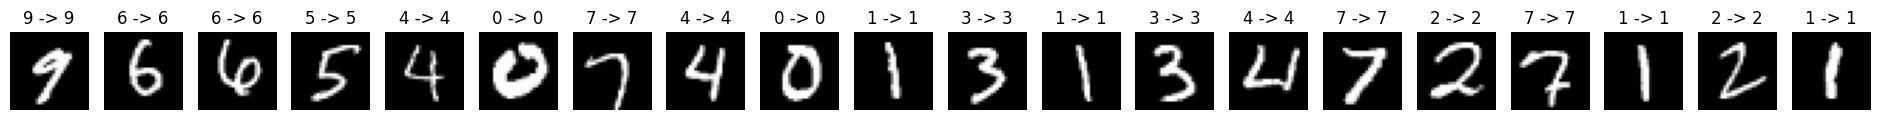

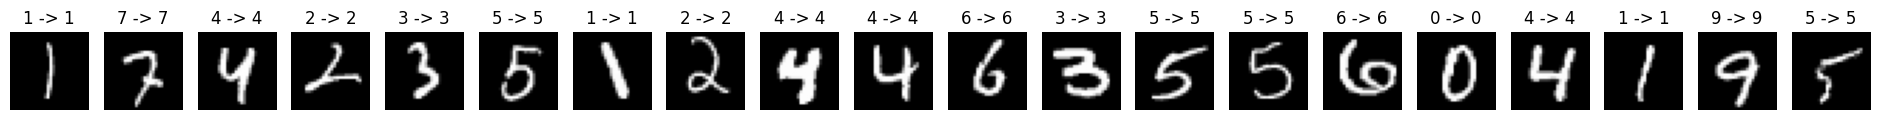

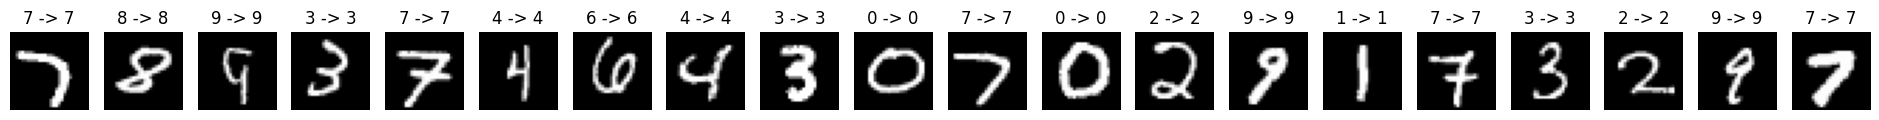

In [6]:
model.eval()
with torch.no_grad():
    correct = 0
    total = 0
    for i, (images, labels) in enumerate(test_loader):
        images = images.cuda()
        labels = labels.cuda()

        outputs = model(images)
        confidences = outputs.softmax(1)
        _, predicted = torch.max(outputs.data, 1)
        correct_idx = predicted == labels
        incorrect_idx = predicted != labels

        if i == 0:
            correct_images = images[correct_idx]
            correct_labels = labels[correct_idx]
            correct_pred = predicted[correct_idx]
            correct_conf = confidences[correct_idx]

            incorrect_images = images[incorrect_idx]
            incorrect_labels = labels[incorrect_idx]
            incorrect_pred = predicted[incorrect_idx]
            incorrect_conf = confidences[incorrect_idx]
        else:
            correct_images = torch.cat((correct_images, images[correct_idx]), 0)
            correct_labels = torch.cat((correct_labels, labels[correct_idx]), 0)
            correct_pred = torch.cat((correct_pred, predicted[correct_idx]), 0)
            correct_conf = torch.cat((correct_conf, confidences[correct_idx]), 0)

            incorrect_images = torch.cat((incorrect_images, images[incorrect_idx]), 0)
            incorrect_labels = torch.cat((incorrect_labels, labels[incorrect_idx]), 0)
            incorrect_pred = torch.cat((incorrect_pred, predicted[incorrect_idx]), 0)
            incorrect_conf = torch.cat((incorrect_conf, confidences[incorrect_idx]), 0)

print("Incorrect Predictions:")
plt_num = 20
for i in range(4):
    show_images_withPred(
        incorrect_images[i*plt_num:(i+1)*plt_num],
        incorrect_labels[i*plt_num:(i+1)*plt_num],
        incorrect_pred[i*plt_num:(i+1)*plt_num],
        incorrect_conf[i*plt_num:(i+1)*plt_num]
    )

print("\n\nCorrect Predictions:")
for i in range(4):
    show_images_withPred(
        correct_images[i*plt_num:(i+1)*plt_num],
        correct_labels[i*plt_num:(i+1)*plt_num],
        correct_pred[i*plt_num:(i+1)*plt_num],
        correct_conf[i*plt_num:(i+1)*plt_num]
    )

# Freeing memory by deleting large tensors after usage
del correct_images, correct_labels, correct_pred, correct_conf
del incorrect_images, incorrect_labels, incorrect_pred, incorrect_conf


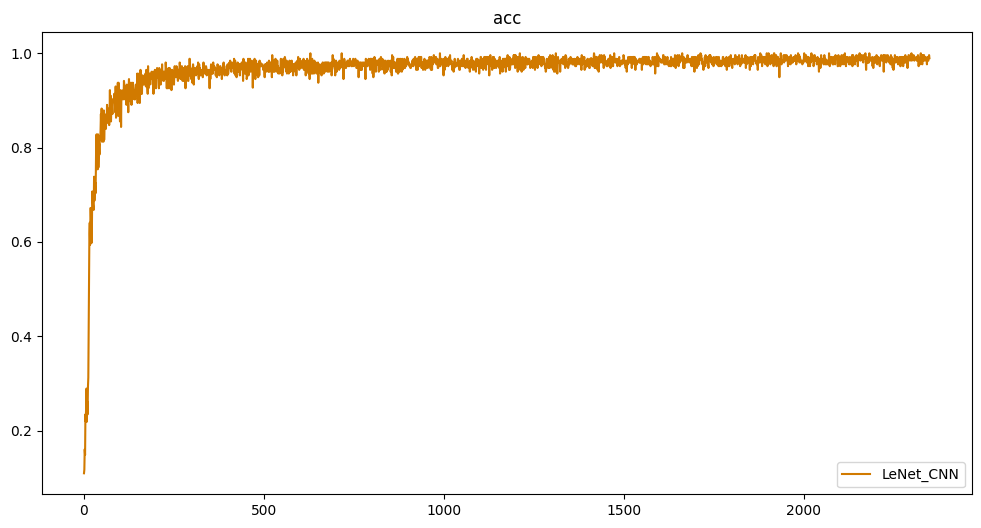

Text(0.5, 1.0, 'loss')

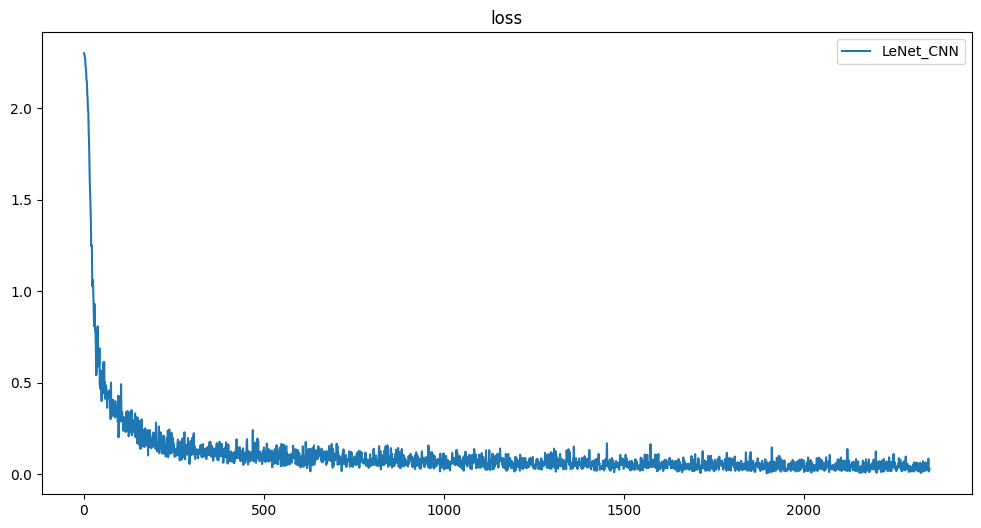

In [ ]:
plt.figure(figsize=(12, 6))
# plt.plot(acc_list, color='#1A62AE')  # DNN color: Blue
plt.plot(acc_list_cnn, color='#D17A00')  # LeNet_CNN color: Orange
# plt.legend(['DNN', 'LeNet_CNN'])
plt.legend(['LeNet_CNN'])
plt.title('acc')
plt.show()


plt.figure(figsize=(12,6))
# plt.plot(loss_list)
plt.plot(loss_list_cnn)
# plt.legend(['DNN','LeNet_CNN'])
plt.legend(['LeNet_CNN'])
plt.title('loss')

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


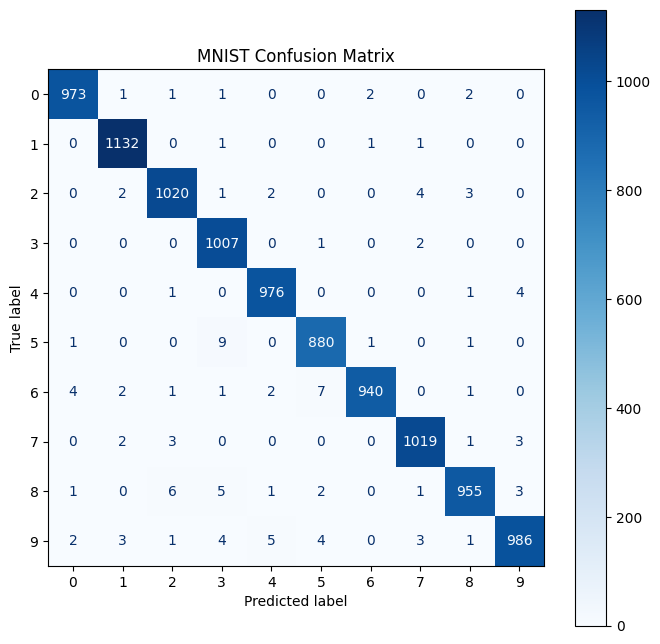

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.cuda()
        labels = labels.cuda()

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("MNIST Confusion Matrix")
plt.show()

In [8]:

# FGSM Adversarial Attack
# This function creates adversarial images by adding
# small perturbations designed to confuse the CNN.

def fgsm(model, criterion, images, labels, step_size):

    # Prepare the images for gradient calculation
    images = images.clone().detach().requires_grad_(True)

    # Get the model's predictions
    outputs = model(images)

    # Clear previous gradients
    model.zero_grad()

    # Calculate the loss
    loss = criterion(outputs, labels)

    # Calculate gradients with respect to the images
    loss.backward()

    # Generate adversarial images using FGSM
    ae_images = images + step_size * images.grad.sign()

    # Keep pixel values between 0 and 1
    ae_images = torch.clamp(ae_images, 0, 1)

    # Return the adversarial images
    return ae_images.detach()


In [9]:

# Test the CNN model against FGSM adversarial examples

model.eval()

correct = 0
total = 0

# Set the strength of the adversarial attack
epsilon = 0.20

# Test the model using adversarial images
for images, labels in test_loader:

    # Move images and labels to the same device as the model
    device = next(model.parameters()).device
    images = images.to(device)
    labels = labels.to(device)

    # Generate adversarial images using FGSM
    ae_images = fgsm(model, criterion, images, labels, epsilon)

    # Get predictions for adversarial images
    with torch.no_grad():
        outputs = model(ae_images)
        _, predicted = torch.max(outputs, 1)

    # Calculate accuracy
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

# Display the accuracy
adversarial_accuracy = 100 * correct / total

print(f"Original CNN Accuracy: 98.77%")
print(f"FGSM Adversarial Accuracy: {adversarial_accuracy:.2f}%")
print(f"Accuracy Decrease: {98.77 - adversarial_accuracy:.2f} percentage points")


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Original CNN Accuracy: 98.77%
FGSM Adversarial Accuracy: 11.70%
Accuracy Decrease: 87.07 percentage points


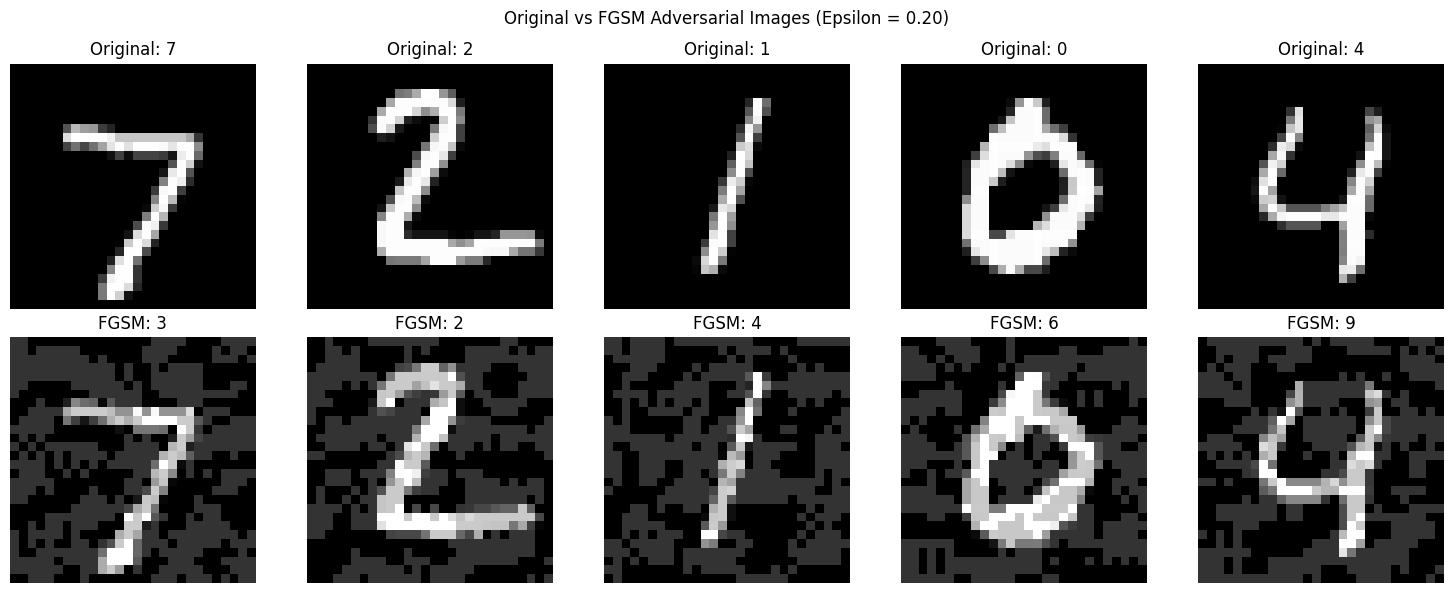

In [10]:

# Compare original and FGSM adversarial images

model.eval()

# Get one batch of test images
images, labels = next(iter(test_loader))

device = next(model.parameters()).device
images = images.to(device)
labels = labels.to(device)

# Generate adversarial images
ae_images = fgsm(model, criterion, images, labels, step_size=0.20)

# Get predictions for original and adversarial images
with torch.no_grad():
    original_outputs = model(images)
    adversarial_outputs = model(ae_images)

    original_preds = original_outputs.argmax(dim=1)
    adversarial_preds = adversarial_outputs.argmax(dim=1)

# Display 5 original and adversarial images
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(5):

    # Original images
    axes[0, i].imshow(images[i].detach().cpu().squeeze(), cmap='gray')
    axes[0, i].set_title(f"Original: {original_preds[i].item()}")
    axes[0, i].axis('off')

    # Adversarial images
    axes[1, i].imshow(ae_images[i].detach().cpu().squeeze(), cmap='gray')
    axes[1, i].set_title(f"FGSM: {adversarial_preds[i].item()}")
    axes[1, i].axis('off')

plt.suptitle("Original vs FGSM Adversarial Images (Epsilon = 0.20)")
plt.tight_layout()
plt.show()


Epsilon: 0.00 | Accuracy: 98.88%
Epsilon: 0.05 | Accuracy: 89.86%
Epsilon: 0.10 | Accuracy: 58.55%
Epsilon: 0.15 | Accuracy: 27.05%
Epsilon: 0.20 | Accuracy: 11.70%


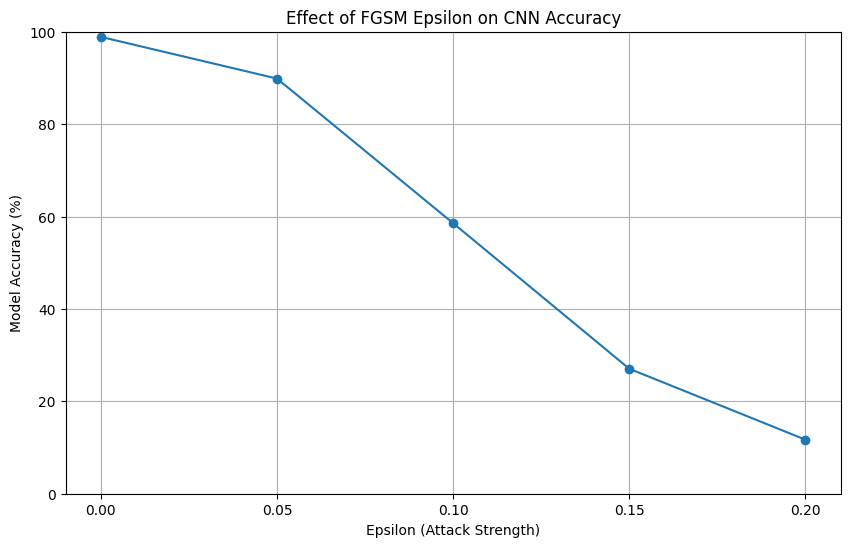

In [11]:

# Evaluate FGSM attacks using different epsilon values

model.eval()

epsilon_values = [0.00, 0.05, 0.10, 0.15, 0.20]
fgsm_accuracies = []

device = next(model.parameters()).device

for epsilon in epsilon_values:

    correct = 0
    total = 0

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Generate adversarial images
        ae_images = fgsm(model, criterion, images, labels, epsilon)

        # Evaluate the model
        with torch.no_grad():
            outputs = model(ae_images)
            predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    accuracy = 100 * correct / total
    fgsm_accuracies.append(accuracy)

    print(f"Epsilon: {epsilon:.2f} | Accuracy: {accuracy:.2f}%")

# Plot epsilon values against model accuracy
plt.figure(figsize=(10, 6))
plt.plot(epsilon_values, fgsm_accuracies, marker='o')

plt.title("Effect of FGSM Epsilon on CNN Accuracy")
plt.xlabel("Epsilon (Attack Strength)")
plt.ylabel("Model Accuracy (%)")
plt.xticks(epsilon_values)
plt.ylim(0, 100)
plt.grid(True)
plt.show()


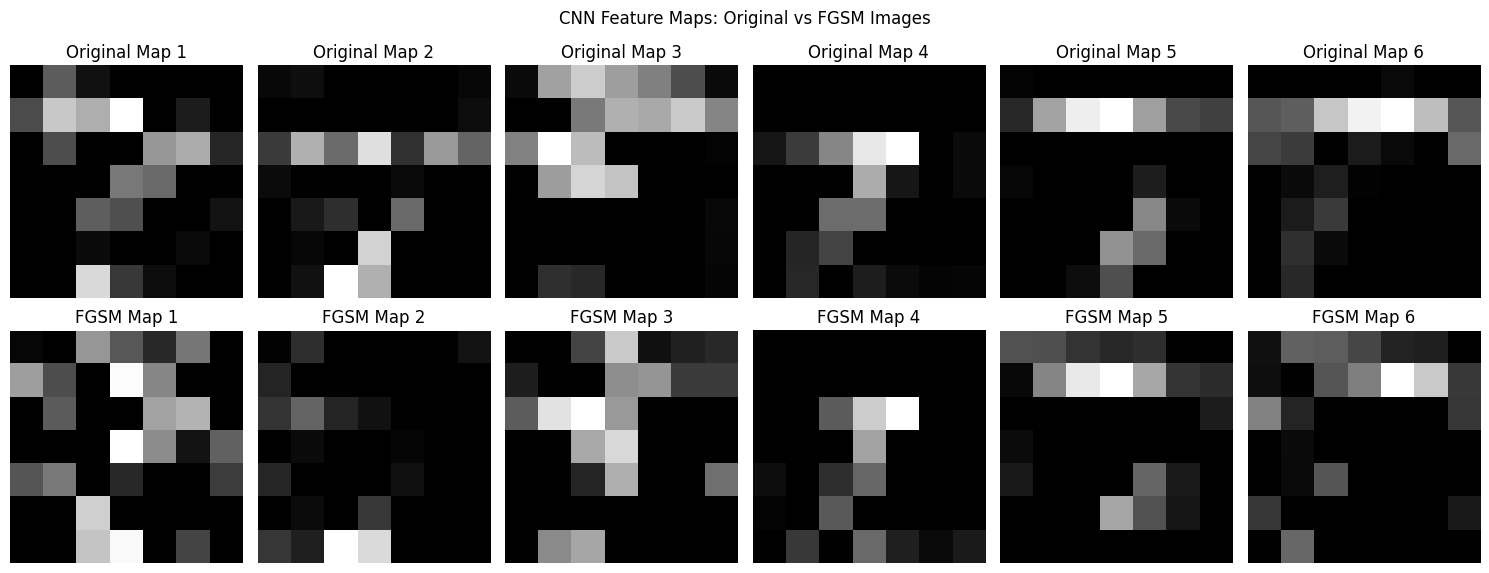

In [12]:

# Compare CNN feature maps for original and adversarial images

model.eval()

device = next(model.parameters()).device

# Get one image from the MNIST test dataset
images, labels = next(iter(test_loader))
images = images.to(device)
labels = labels.to(device)

# Select the first image
original_image = images[:1]
original_label = labels[:1]

# Generate an adversarial version using FGSM
adversarial_image = fgsm(
    model, criterion, original_image, original_label, step_size=0.20
)

# Extract feature maps from the convolutional layers
with torch.no_grad():
    original_features = model.features[:6](original_image)
    adversarial_features = model.features[:6](adversarial_image)

# Display feature maps side by side
fig, axes = plt.subplots(2, 6, figsize=(15, 6))

for i in range(6):

    # Original feature maps
    axes[0, i].imshow(
        original_features[0, i].cpu(), cmap='gray'
    )
    axes[0, i].set_title(f"Original Map {i+1}")
    axes[0, i].axis('off')

    # Adversarial feature maps
    axes[1, i].imshow(
        adversarial_features[0, i].cpu(), cmap='gray'
    )
    axes[1, i].set_title(f"FGSM Map {i+1}")
    axes[1, i].axis('off')

plt.suptitle("CNN Feature Maps: Original vs FGSM Images")
plt.tight_layout()
plt.show()


In [13]:

# Random Noise Attack
# Compare random perturbations against FGSM

def rand_noise_attack(images, step_size):

    # Generate random noise
    rand_perturbation = torch.randn_like(images)

    # Add random noise to the images
    ae_images = images + step_size * rand_perturbation.sign()

    # Keep pixel values between 0 and 1
    ae_images = torch.clamp(ae_images, 0, 1)

    return ae_images.detach()


# Evaluate the CNN using random noise
model.eval()

correct = 0
total = 0

device = next(model.parameters()).device

for images, labels in test_loader:

    images = images.to(device)
    labels = labels.to(device)

    # Generate images with random noise
    ae_images = rand_noise_attack(images, step_size=0.20)

    # Test the model
    with torch.no_grad():
        outputs = model(ae_images)
        predicted = outputs.argmax(dim=1)

    total += labels.size(0)
    correct += (predicted == labels).sum().item()

random_noise_accuracy = 100 * correct / total

print(f"Random Noise Accuracy: {random_noise_accuracy:.2f}%")
print(f"FGSM Accuracy: {fgsm_accuracies[-1]:.2f}%")



Random Noise Accuracy: 98.02%
FGSM Accuracy: 11.70%


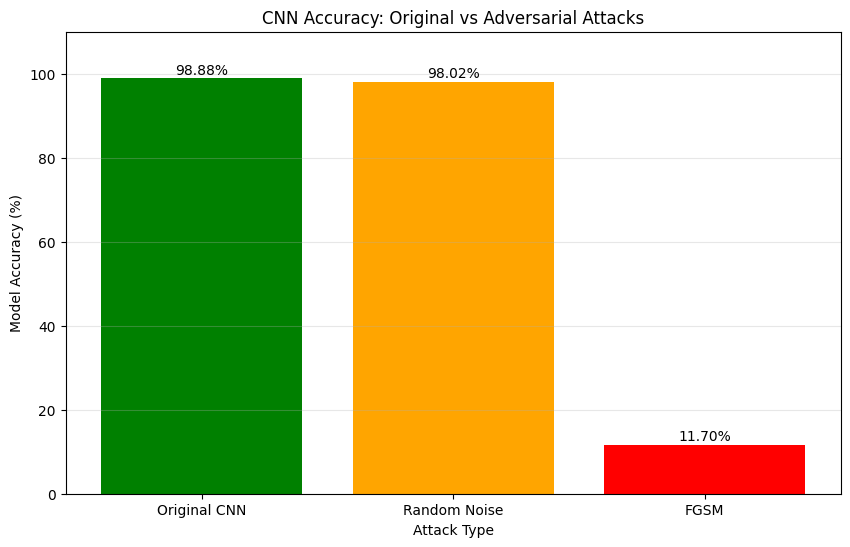

In [14]:

# Compare original CNN, Random Noise, and FGSM accuracy

# Accuracy results from the experiments
attack_types = ['Original CNN', 'Random Noise', 'FGSM']
accuracy_values = [
    fgsm_accuracies[0],
    random_noise_accuracy,
    fgsm_accuracies[-1]
]

# Create a bar graph
plt.figure(figsize=(10, 6))

bars = plt.bar(
    attack_types,
    accuracy_values,
    color=['green', 'orange', 'red']
)

# Add accuracy percentages above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f'{height:.2f}%',
        ha='center'
    )

plt.title('CNN Accuracy: Original vs Adversarial Attacks')
plt.xlabel('Attack Type')
plt.ylabel('Model Accuracy (%)')
plt.ylim(0, 110)
plt.grid(axis='y', alpha=0.3)

plt.show()


In [15]:

# Hyperparameter Experiment: Learning Rate Comparison
# Create a second CNN without modifying the original model

# Keep the original learning rate for comparison
original_learning_rate = 0.001

# Test a smaller learning rate
new_learning_rate = 0.0005

# Create a new instance of the same CNN architecture
model_lr = LeNet().to(next(model.parameters()).device)

# Use the same loss function as the original CNN
criterion_lr = nn.CrossEntropyLoss()

# Create a new optimizer with the smaller learning rate
optimizer_lr = torch.optim.Adam(
    model_lr.parameters(),
    lr=new_learning_rate
)

print("Original Learning Rate:", original_learning_rate)
print("New Learning Rate:", new_learning_rate)
print("Second CNN created successfully!")


Original Learning Rate: 0.001
New Learning Rate: 0.0005
Second CNN created successfully!


In [16]:

# Train the second CNN with learning rate 0.0005

model_lr.train()

loss_list_lr = []
acc_list_lr = []

device = next(model_lr.parameters()).device

for epoch in range(num_epochs):

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model_lr(images)
        loss = criterion_lr(outputs, labels)

        # Backpropagation and optimization
        optimizer_lr.zero_grad()
        loss.backward()
        optimizer_lr.step()

        # Track training results
        running_loss += loss.item()
        predictions = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    loss_list_lr.append(epoch_loss)
    acc_list_lr.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}], "
        f"Loss: {epoch_loss:.4f}, "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

print("Second CNN training completed!")


Epoch [1/10], Loss: 0.7109, Accuracy: 78.49%
Epoch [2/10], Loss: 0.2018, Accuracy: 93.96%
Epoch [3/10], Loss: 0.1343, Accuracy: 95.92%
Epoch [4/10], Loss: 0.1049, Accuracy: 96.81%
Epoch [5/10], Loss: 0.0879, Accuracy: 97.31%
Epoch [6/10], Loss: 0.0802, Accuracy: 97.52%
Epoch [7/10], Loss: 0.0720, Accuracy: 97.71%
Epoch [8/10], Loss: 0.0651, Accuracy: 97.97%
Epoch [9/10], Loss: 0.0604, Accuracy: 98.14%
Epoch [10/10], Loss: 0.0564, Accuracy: 98.19%
Second CNN training completed!


In [17]:

# Evaluate second CNN with learning rate 0.0005

model_lr.eval()

device = next(model_lr.parameters()).device

clean_correct = 0
fgsm_correct = 0
total = 0

for images, labels in test_loader:

    images = images.to(device)
    labels = labels.to(device)

    # Test the model on original images
    with torch.no_grad():
        clean_outputs = model_lr(images)
        clean_predictions = clean_outputs.argmax(dim=1)

    clean_correct += (clean_predictions == labels).sum().item()

    # Generate FGSM adversarial images
    ae_images = fgsm(
        model_lr,
        criterion_lr,
        images,
        labels,
        step_size=0.20
    )

    # Test the model on adversarial images
    with torch.no_grad():
        fgsm_outputs = model_lr(ae_images)
        fgsm_predictions = fgsm_outputs.argmax(dim=1)

    fgsm_correct += (fgsm_predictions == labels).sum().item()

    total += labels.size(0)

# Calculate final accuracies
clean_accuracy_lr = 100 * clean_correct / total
fgsm_accuracy_lr = 100 * fgsm_correct / total

print("Learning Rate: 0.0005")
print(f"Clean Test Accuracy: {clean_accuracy_lr:.2f}%")
print(f"FGSM Test Accuracy: {fgsm_accuracy_lr:.2f}%")
print(f"Accuracy Decrease: {clean_accuracy_lr - fgsm_accuracy_lr:.2f} percentage points")



Learning Rate: 0.0005
Clean Test Accuracy: 98.81%
FGSM Test Accuracy: 4.81%
Accuracy Decrease: 94.00 percentage points


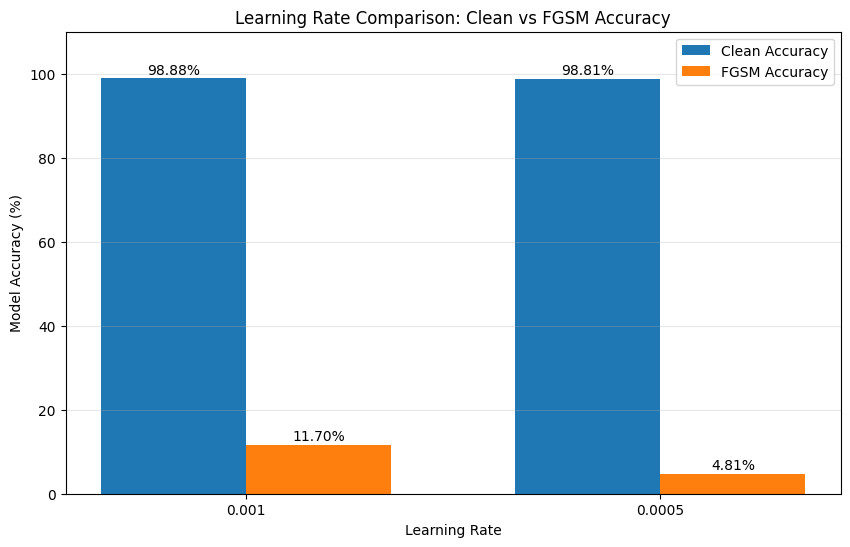

In [18]:

# Compare CNN accuracy across two learning rates

learning_rates = ['0.001', '0.0005']

clean_accuracies = [fgsm_accuracies[0], clean_accuracy_lr]
adversarial_accuracies = [fgsm_accuracies[-1], fgsm_accuracy_lr]

x = np.arange(len(learning_rates))
width = 0.35

plt.figure(figsize=(10, 6))

bars1 = plt.bar(
    x - width/2,
    clean_accuracies,
    width,
    label='Clean Accuracy'
)

bars2 = plt.bar(
    x + width/2,
    adversarial_accuracies,
    width,
    label='FGSM Accuracy'
)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 1,
            f'{height:.2f}%',
            ha='center'
        )

plt.xlabel('Learning Rate')
plt.ylabel('Model Accuracy (%)')
plt.title('Learning Rate Comparison: Clean vs FGSM Accuracy')
plt.xticks(x, learning_rates)
plt.ylim(0, 110)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()
